In [1]:
import os
from pathlib import Path

os.chdir(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())

In [3]:
import pandas as pd

cluster3 = pd.read_csv('./results/PPI/cluster3_annotations.tsv', sep='\t')
cluster3_genes = cluster3['#node'].tolist()
print(f"Cluster 3 genes: {len(cluster3_genes)}")

consensus_df = pd.read_csv('./results/DEG/consensus_DEGs.csv')

cluster3_directions = consensus_df[consensus_df['Gene'].isin(cluster3_genes)]
up = (cluster3_directions['direction'] == 'Up').sum()
down = (cluster3_directions['direction'] == 'Down').sum()

print(f"Upregulated: {up} ({up/len(cluster3_directions)*100:.1f}%)")
print(f"Downregulated: {down} ({down/len(cluster3_directions)*100:.1f}%)")

Cluster 3 genes: 45
Upregulated: 8 (17.8%)
Downregulated: 37 (82.2%)


In [5]:
mcc_raw_c3 = pd.read_csv('./results/PPI/cluster3_MCC_top10.csv', skiprows=1)
betweenness_raw_c3 = pd.read_csv('./results/PPI/cluster3_betweenness_top10.csv', skiprows=1)

ensp_to_gene = dict(zip(
    cluster3['identifier'].str.replace('9606.', '', regex=False),
    cluster3['#node']
))

mcc_ids_c3 = [id.replace('9606.', '') for id in mcc_raw_c3['Name'].tolist()]
betweenness_ids_c3 = [id.replace('9606.', '') for id in betweenness_raw_c3['Name'].tolist()]

mcc_genes_c3 = [ensp_to_gene.get(id, id) for id in mcc_ids_c3]
betweenness_genes_c3 = [ensp_to_gene.get(id, id) for id in betweenness_ids_c3]

mcc_only_c3 = set(mcc_genes_c3) - set(betweenness_genes_c3)
betweenness_only_c3 = set(betweenness_genes_c3) - set(mcc_genes_c3)
both_c3 = set(mcc_genes_c3) & set(betweenness_genes_c3)

print("MCC top 10:", mcc_genes_c3)
print("Betweenness top 10:", betweenness_genes_c3)
print(f"MCC only: {mcc_only_c3}")
print(f"Betweenness only: {betweenness_only_c3}")
print(f"Both: {both_c3}")
print(f"Overlap count: {len(both_c3)}")

MCC top 10: ['FOS', 'EGR1', 'FOSB', 'IER2', 'ATF3', 'JUNB', 'DUSP1', 'ZFP36', 'EGR2', 'MYC']
Betweenness top 10: ['FOS', 'MYC', 'CEBPB', 'EGR2', 'HDAC2', 'ATF3', 'EGR1', 'CEBPD', 'CCND1', 'EZH2']
MCC only: {'JUNB', 'DUSP1', 'FOSB', 'IER2', 'ZFP36'}
Betweenness only: {'CCND1', 'CEBPD', 'EZH2', 'HDAC2', 'CEBPB'}
Both: {'EGR2', 'ATF3', 'MYC', 'FOS', 'EGR1'}
Overlap count: 5


In [7]:
edges_c3 = pd.read_csv('./results/PPI/cluster3_edges.tsv', sep='\t')
degrees_c3 = pd.read_csv('./results/PPI/cluster3_degrees.tsv', sep='\t')
print(edges_c3.shape)
print(degrees_c3.head())

(119, 13)
     #node            identifier  node_degree
0    ABCA6  9606.ENSP00000284425            1
1    ASXL3  9606.ENSP00000269197            1
2     ATF3  9606.ENSP00000344352           13
3     BCL6  9606.ENSP00000384371            6
4  BHLHE40  9606.ENSP00000256495            2


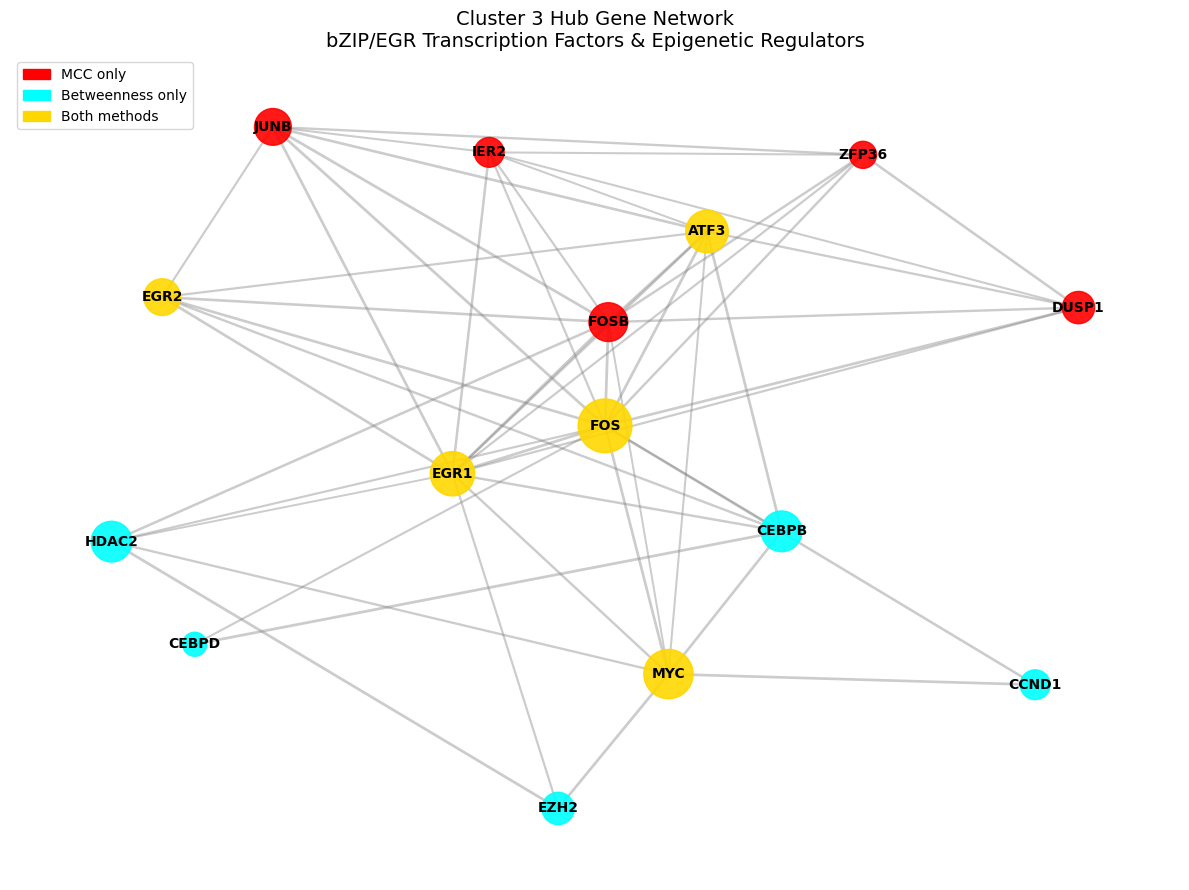

In [9]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

all_hubs_c3 = set(mcc_genes_c3) | set(betweenness_genes_c3)

hub_edges_c3 = edges_c3[
    (edges_c3['#node1'].isin(all_hubs_c3)) & 
    (edges_c3['node2'].isin(all_hubs_c3))
]

G3 = nx.Graph()
for _, row in hub_edges_c3.iterrows():
    G3.add_edge(row['#node1'], row['node2'], weight=row['combined_score'])

color_map_c3 = []
for node in G3.nodes():
    if node in both_c3:
        color_map_c3.append('gold')
    elif node in mcc_only_c3:
        color_map_c3.append('red')
    else:
        color_map_c3.append('cyan')

degrees = []
for node in G3.nodes():
    deg = degrees_c3[degrees_c3['#node'] == node]['node_degree'].values
    degrees.append(deg[0] if len(deg) > 0 else 1)

min_deg, max_deg = min(degrees), max(degrees)
node_sizes = [300 + (d - min_deg) / (max_deg - min_deg) * 1200 for d in degrees]

edge_weights = [G3[u][v]['weight'] * 2 for u, v in G3.edges()]

plt.figure(figsize=(12, 9))
pos = nx.spring_layout(G3, seed=42, k=2)

nx.draw_networkx_nodes(G3, pos, node_color=color_map_c3, node_size=node_sizes, alpha=0.9)
nx.draw_networkx_edges(G3, pos, width=edge_weights, alpha=0.4, edge_color='grey')
nx.draw_networkx_labels(G3, pos, font_size=10, font_weight='bold')

legend = [mpatches.Patch(color='red', label='MCC only'),
          mpatches.Patch(color='cyan', label='Betweenness only'),
          mpatches.Patch(color='gold', label='Both methods')]
plt.legend(handles=legend, loc='upper left')

plt.title('Cluster 3 Hub Gene Network\nbZIP/EGR Transcription Factors & Epigenetic Regulators', fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.savefig('./figures/cluster3_hub_network.png', dpi=300)
plt.show()

In [11]:
consensus = pd.read_csv('./results/DEG/consensus_DEGs.csv')
hub_directions_df = consensus[consensus['Gene'].isin(all_hubs_c3)]
c3_direction = hub_directions_df.set_index('Gene')['direction']

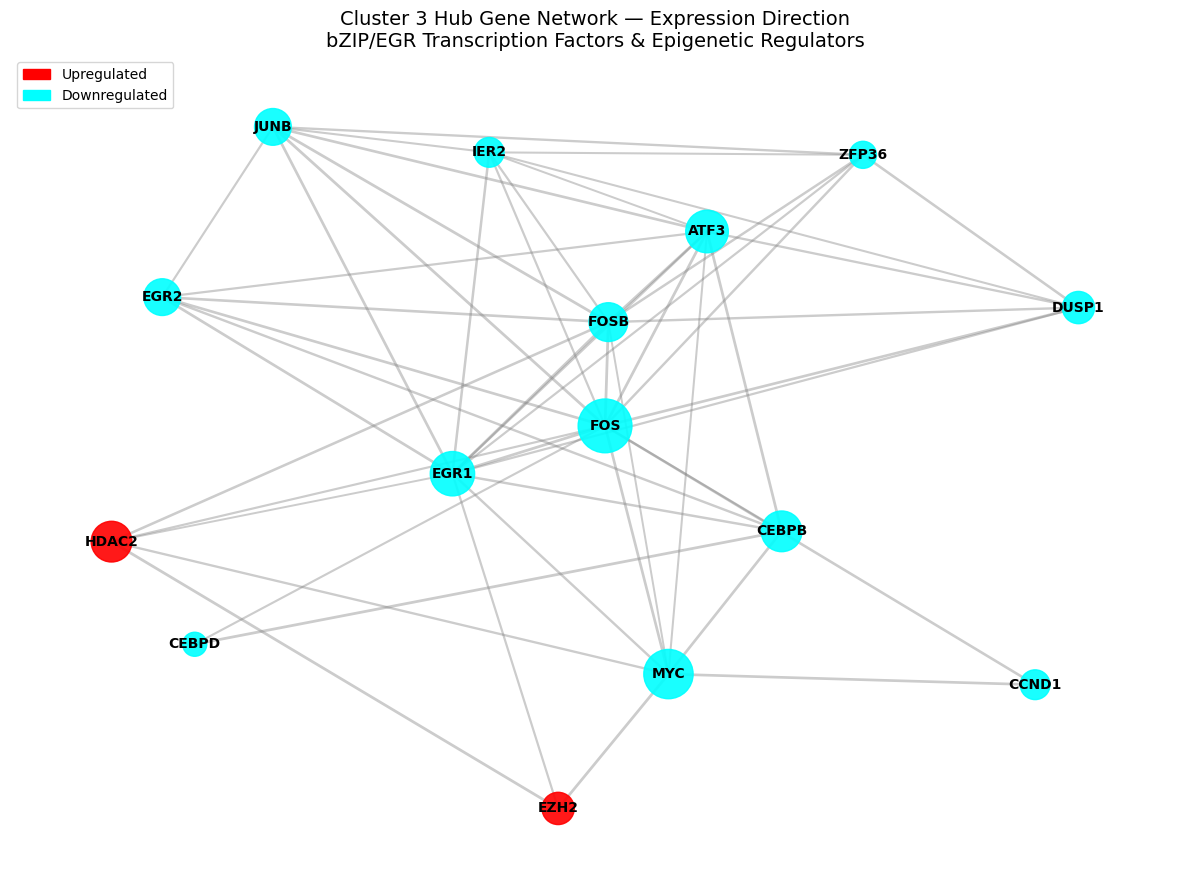

In [13]:
color_map_c3_dir = []
for node in G3.nodes():
    if node in c3_direction.index:
        color_map_c3_dir.append('red' if c3_direction[node] == 'Up' else 'cyan')
    else:
        color_map_c3_dir.append('cyan')  # default to down if not found

plt.figure(figsize=(12, 9))
pos = nx.spring_layout(G3, seed=42, k=2)
nx.draw_networkx_nodes(G3, pos, node_color=color_map_c3_dir, node_size=node_sizes, alpha=0.9)
nx.draw_networkx_edges(G3, pos, width=edge_weights, alpha=0.4, edge_color='grey')
nx.draw_networkx_labels(G3, pos, font_size=10, font_weight='bold')

legend = [mpatches.Patch(color='red', label='Upregulated'),
          mpatches.Patch(color='cyan', label='Downregulated')]
plt.legend(handles=legend, loc='upper left')
plt.title('Cluster 3 Hub Gene Network — Expression Direction\nbZIP/EGR Transcription Factors & Epigenetic Regulators', fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.savefig('./figures/cluster3_hub_network_direction.png', dpi=300)
plt.show()